# Air raid alerts in Ukraine — training and validation

**Task.** For every oblast, every hour, predict

$$P(\text{the oblast is under air raid alert at some point in the next } h \text{ hours}), \qquad h \in \{1, 3, 6\}.$$

| | |
|---|---|
| forecast time | end of every hour *t* (T = t + 1 h); only information available at T is used |
| target | `y_h = 1` if any oblast- or raion-level alert is active in the oblast during hours t+1 … t+h |
| data | official alerts, **2025-11-01 → 2026-09-04 00:00 Kyiv** (raion-level alerting, before the yellow/red system) — see `eda.ipynb` |
| validation | 4 two-week folds spread over **Feb – Jun 2026**: hyperparameter tuning and seasonal robustness |
| test | the **last 5 weeks** before 4 Sep 2026 in 4 rolling folds — used once, after all choices were made |
| metrics | Brier score (main), log loss, ROC AUC — pooled and per oblast; separately for hours with and without an active alert |

The code lives in `ua_alerts/` (`features.py`, `models.py`, `tuning.py`, `backtest.py`, `evaluation.py`); this notebook runs and explains it.

In [1]:
import sys, json; sys.path.insert(0, "..")
%matplotlib inline
import pandas as pd
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 100)
from ua_alerts import backtest, config, data, evaluation, features, models

## 1. Data and features

The hourly alert state of each oblast is turned into a panel with one row per (hour, oblast).
All features are computed from hours ≤ t:

| group | features | motivation (EDA) |
|---|---|---|
| own state | `active_now` (alert at the forecast moment), `cov_0`, `cov_1` (share of the last two hours under alert), `hours_in_alert`, `hours_quiet` | persistence dominates short-term dynamics |
| own history | rolling share under alert over 3 h / 6 h / 24 h / 7 d, alert starts in the last 1 / 6 / 24 h, same hour yesterday / last 7 days | recent level matters more than long-term averages |
| regional state | national share under alert, number of oblasts with new alerts in the last 1 / 3 h, share under alert and new alerts per macro-region (west / center / south / front) | alerts propagate between rear oblasts (onset lift 10–23×) |
| calendar | Kyiv hour of the first target hour | daily cycle with up to 7× amplitude in the rear |
| identity | `region_id` (categorical) | base rates differ from 1 % to 96 % |

Day of week and month are deliberately left out — the EDA found no evidence for them.

In [2]:
panel, indicator = backtest.load_inputs()
window = panel.loc[pd.Timestamp(config.REGIME_START):]
print(f"panel: {len(panel):,} rows (hour x oblast); modelling window: {len(window):,} rows, "
      f"{window.index.get_level_values('time').nunique():,} forecast hours x {window.index.get_level_values('region').nunique()} oblasts")
pd.DataFrame({"mean": window[features.FEATURES[:-1]].mean(), "std": window[features.FEATURES[:-1]].std()}).round(3).T

panel: 940,728 rows (hour x oblast); modelling window: 176,808 rows, 7,367 forecast hours x 24 oblasts


,active_now,cov_0,cov_1,cov_mean_3h,cov_mean_6h,cov_mean_24h,cov_mean_168h,starts_1h,starts_6h,starts_24h,hours_in_alert,hours_quiet,cov_same_hour_1d,cov_same_hour_7d,national_active,national_starts_1h,national_starts_3h,west_active,center_active,south_active,front_active,west_starts_3h,center_starts_3h,south_starts_3h,front_starts_3h,hour
mean,0.277,0.277,0.277,0.277,0.277,0.277,0.277,0.490,2.940,11.743,11.904,35.655,0.277,0.277,0.277,4.177,8.219,0.021,0.145,0.240,0.792,0.412,2.140,1.577,4.090,11.501
std,0.448,0.415,0.415,0.386,0.368,0.342,0.324,1.372,4.414,13.718,45.764,77.632,0.415,0.340,0.138,3.075,3.931,0.113,0.228,0.326,0.239,1.498,2.075,1.145,1.327,6.922


### Leakage test

For random forecast times T, the features are rebuilt from a dataset **truncated at T** (alerts still running at T are cut at T,
nothing after T exists) and compared with the features built from the full data — they must be identical. The test was also
checked to *fail* when a one-hour look-ahead was injected on purpose (`cov_1 = cov.shift(-1)`), so it does detect leakage.

In [3]:
from tests.test_leakage import test_features_do_not_use_future_data
test_features_do_not_use_future_data()
print("leakage test passed: features at time T are identical with and without data after T")

leakage test passed: features at time T are identical with and without data after T


## 2. Validation design

* **Two sets of folds.** *Validation*: 4 two-week folds spread over Feb–Jun 2026 (winter, spring, early summer) — used to tune
  hyperparameters and to check that conclusions are not specific to one season. *Test*: the last 35 days before 4 Sep 2026 in
  4 consecutive folds (~8.75 days each) — the "latest period" required by the task, evaluated once with the tuned settings.
* **Rolling origin.** Every fold is forecast by models trained only on data before it; models are re-trained per fold and, within a
  fold, forecast every hour from the actually observed data up to that hour (like a model retrained every ~9 days in production).
* **Two training-window schemes.** *Expanding*: train on everything since 2025-11-01. *Sliding*: only the 12 weeks before the fold.
* **Purging.** A training row at hour t has the target window t+1 … t+h; rows whose target window reaches into the evaluated fold are dropped.
* **Metrics.** Brier score is the main metric (it rewards ranking and calibration). Log loss punishes confident mistakes.
  ROC AUC is reported **pooled** and as the **mean of per-oblast AUCs** — pooled AUC is inflated because any model that separates
  front-line oblasts (alert 95 % of the time) from the west (1–3 %) gets a high pooled AUC.
  *Brier skill* = 1 − Brier(model) / Brier(hour-of-day rate).

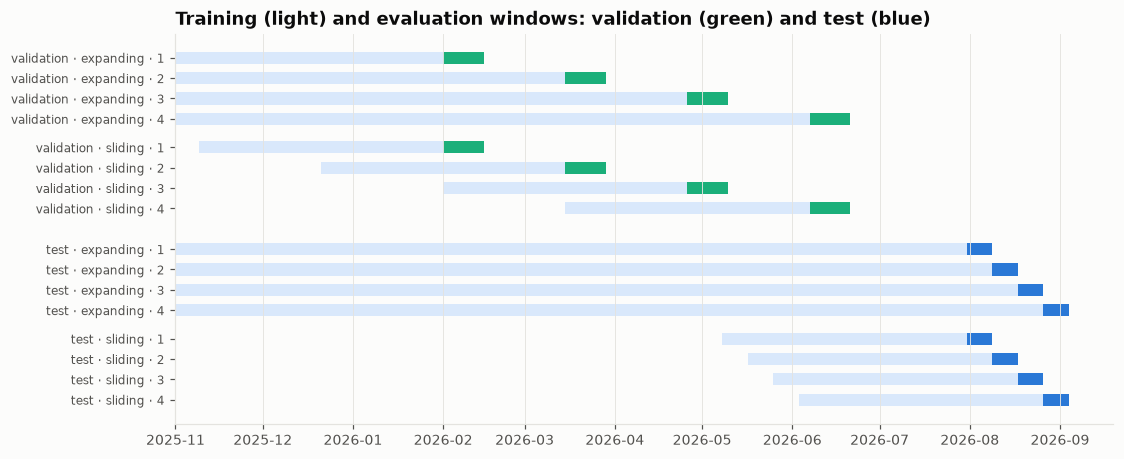

In [4]:
evaluation.plot_folds()

## 3. Models

| group | model | idea |
|---|---|---|
| baseline | **persistence** | an alert active now continues; no alert now stays quiet (naive walk without drift — drift is meaningless for a bounded 0/1 series) |
| baseline | **hour-of-day rate** | training frequency of `y_h` per oblast and Kyiv hour |
| ETS | **ETS(A,N,N), ETS(A,N,A), ETS(A,A,A), ETS(A,Ad,A)** | additive exponential smoothing of the hourly 0/1 alert indicator per oblast, seasonal period 24 h. Parameters by maximum likelihood on training data; the filter then runs forward with fixed parameters, so the state at t uses only data ≤ t. The max of the 1…h-step forecasts is mapped to a probability by a **per-oblast** logistic calibration |
| ETS | **AutoETS** | per oblast, the spec with the lowest AICc on the training window. Multiplicative error/seasonality is excluded: the series contains zeros |
| statistical | **logistic AR** | logistic regression on the features above — the binary-data analogue of an autoregressive model |
| ML | **LightGBM**, **XGBoost** | gradient-boosted trees on the same features |

ARIMA was considered and rejected: it models a continuous Gaussian quantity, can forecast outside [0, 1], forecasts the expected
share of an hour under alert rather than P(any alert within h hours), and cannot use other oblasts' state.

## 4. Hyperparameter tuning (validation folds only)

Grid search for the feature-based models; criterion: mean Brier score over the 4 validation folds at h = 3 h, expanding window.
The search is **time-based** — ordinary random k-fold cross-validation would leak, because neighbouring hours are strongly
correlated and would end up on both sides of the split. ETS needs no tuning (maximum likelihood), the baselines have no parameters.

| model | grid |
|---|---|
| logistic AR | C ∈ {0.01, 0.1, 1, 10} |
| LightGBM | num_leaves ∈ {15, 31, 63} × min_child_samples ∈ {50, 200} × (learning rate, trees) ∈ {(0.03, 400), (0.1, 150)} |
| XGBoost | max_depth ∈ {4, 6, 8} × min_child_weight ∈ {5, 20} × (learning rate, trees) ∈ {(0.03, 400), (0.1, 150)} |

In [5]:
tuning = pd.read_csv(config.ROOT / "reports" / "tuning_results.csv")
print("selected:", json.dumps(backtest.load_tuned_params()))
summary = tuning.groupby("model")["mean_brier"].agg(best="min", worst="max", configs="size")
summary["spread_%"] = (100 * (summary.worst / summary.best - 1)).round(1)
summary.round(5)

selected: {"LightGBM": {"num_leaves": 15, "min_child_samples": 50, "learning_rate": 0.03, "n_estimators": 400}, "XGBoost": {"max_depth": 4, "min_child_weight": 5, "learning_rate": 0.03, "n_estimators": 400}, "logistic AR": {"C": 1.0}}


,best,worst,configs,spread_%
model,,,,
LightGBM,0.08364,0.08548,12,2.2
XGBoost,0.08349,0.08610,12,3.1
logistic AR,0.08468,0.08535,4,0.8


In [6]:
tuning.sort_values(["model", "mean_brier"]).groupby("model").head(3).round(5)

,model,params,mean_brier,fold_1,fold_2,fold_3,fold_4
4,LightGBM,"{""num_leaves"": 15, ""min_child_samples"": 50, ""learning_rate"": 0.03, ""n_estimators"": 400}",0.08364,0.10041,0.07428,0.07991,0.07996
6,LightGBM,"{""num_leaves"": 15, ""min_child_samples"": 200, ""learning_rate"": 0.03, ""n_estimators"": 400}",0.08373,0.10083,0.07414,0.08015,0.07981
8,LightGBM,"{""num_leaves"": 31, ""min_child_samples"": 50, ""learning_rate"": 0.03, ""n_estimators"": 400}",0.08383,0.10056,0.07523,0.07971,0.07980
16,XGBoost,"{""max_depth"": 4, ""min_child_weight"": 5, ""learning_rate"": 0.03, ""n_estimators"": 400}",0.08349,0.10060,0.07348,0.08036,0.07953
18,XGBoost,"{""max_depth"": 4, ""min_child_weight"": 20, ""learning_rate"": 0.03, ""n_estimators"": 400}",0.08358,0.10096,0.07353,0.08056,0.07926
19,XGBoost,"{""max_depth"": 4, ""min_child_weight"": 20, ""learning_rate"": 0.1, ""n_estimators"": 150}",0.08372,0.10151,0.07389,0.08022,0.07925
2,logistic AR,"{""C"": 1.0}",0.08468,0.10458,0.07362,0.08147,0.07904
3,logistic AR,"{""C"": 10.0}",0.08470,0.10457,0.07368,0.08149,0.07905
1,logistic AR,"{""C"": 0.1}",0.08473,0.10466,0.07355,0.08154,0.07919


* **Hyperparameters barely matter here**: the best and worst configuration differ by 2–3 % for the boosters and < 1 % for the
  logistic AR. The search prefers shallower trees (15 leaves / depth 4) to the initial guesses (31 leaves / depth 6).
* The **season matters far more** than the configuration: the same model scores ≈ 0.100 in February and ≈ 0.074 in March.
* On the test set, the tuned XGBoost scores 0.0727 vs 0.0725 with the initial settings — tuning did not improve test performance,
  which is consistent with the flat validation surface. The tuned settings are kept because they were chosen by the pre-defined procedure.

## 5. Training and validation run

Every model is trained and evaluated for every (fold set, window scheme, fold, horizon), with the tuned hyperparameters.
Predictions are cached in `data/processed/backtest_predictions.parquet`; `rerun=True` retrains everything.

In [7]:
preds = backtest.run_all(rerun=False)   # set rerun=True to retrain everything (~6 min); run ua_alerts.tuning first to re-tune
board = backtest.leaderboard(preds)
preds.groupby(["set", "window", "h"]).size().unstack()

h                         1      3      6
set        window                        
test       expanding  20136  20088  20016
           sliding    20136  20088  20016
validation expanding  32256  32256  32256
           sliding    32256  32256  32256

## 6. Test results

Leaderboard on the test folds for h = 3 h (both window schemes):

In [8]:
evaluation.leaderboard_table(board, h=3)

group     brier         brier_skill          log_loss           roc_auc         roc_auc_mean_per_oblast        
window                        expanding sliding   expanding sliding expanding sliding expanding sliding               expanding sliding
model                                                                                                                                  
XGBoost                    ML    0.0727  0.0787      0.3582  0.2902    0.2316  0.2456    0.9651  0.9607                  0.8344  0.8293
LightGBM                   ML    0.0730  0.0790      0.3558  0.2870    0.2321  0.2470    0.9648  0.9604                  0.8356  0.8237
logistic AR       statistical    0.0772  0.0797      0.3185  0.2806    0.2430  0.2489    0.9617  0.9605                  0.8373  0.8386
ETS(A,A,A)                ETS    0.0810  0.0878      0.2851  0.2074    0.2679  0.3203    0.9572  0.9458                  0.7956  0.6695
ETS(A,N,A)                ETS    0.0811  0.0880      0.2840  0.2055    0.2684  0.3211    0.9572  0.9453                  0.7955  0.6387
ETS(A,Ad,A)               ETS    0.0811  0.0880      0.2839  0.2056    0.2684  0.3211    0.9572  0.9453                  0.7954  0.6386
ETS(A,N,N)                ETS    0.0813  0.0870      0.2827  0.2151    0.2691  0.3184    0.9566  0.9460                  0.7770  0.6385
AutoETS                   ETS    0.0814  0.0870      0.2816  0.2151    0.2694  0.3184    0.9565  0.9460                  0.7797  0.6385
hour-of-day rate     baseline    0.1133  0.1108      0.0000  0.0000    0.3663  0.3954    0.9230  0.9215                  0.4766  0.5078
persistence          baseline    0.1691  0.1691     -0.4922 -0.5257    1.5576  1.5576    0.8221  0.8221                  0.7090  0.7090

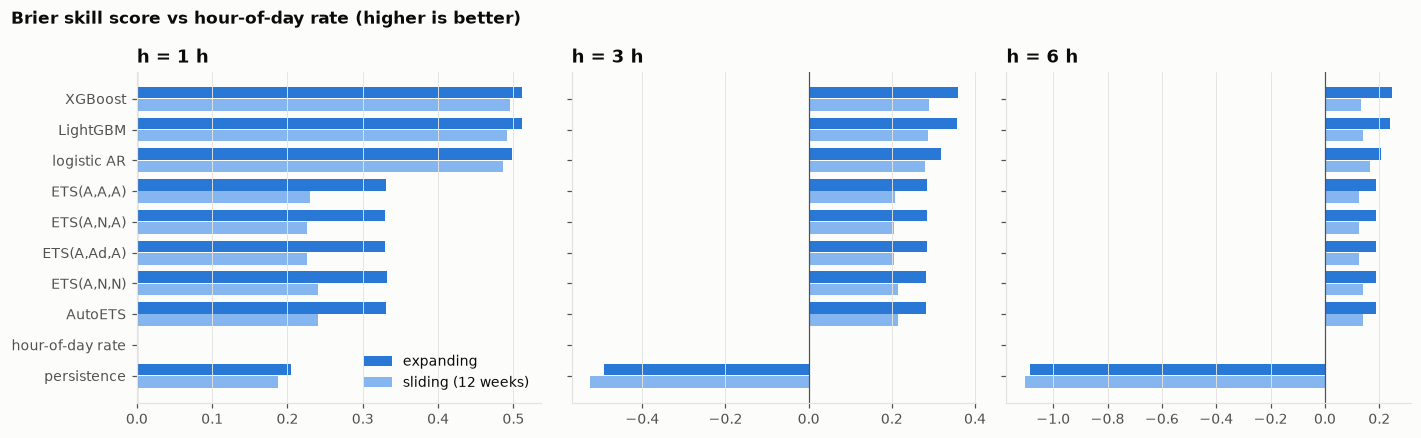

In [9]:
evaluation.plot_skill_by_horizon(board)

* **Ranking**: XGBoost ≈ LightGBM > logistic AR > ETS family > hour-of-day rate > persistence, at every horizon.
  At h = 3 h, XGBoost reaches a Brier score of 0.0727 (skill 0.36 vs the hour-of-day rate), LightGBM 0.0730, logistic AR 0.0772,
  the best ETS 0.081. Skill falls with the horizon (≈ 0.51 at 1 h, 0.36 at 3 h, 0.25 at 6 h).
* **Expanding beats sliding** for every trained model at every horizon, except the hour-of-day rate whose hourly profile drifts.
* **Persistence** is good at 1 h but collapses at 3–6 h, and its hard 0/1 forecasts give a very poor log loss.
* **Correction made during this analysis.** The first ETS version used one logistic calibration pooled over all oblasts; the
  calibration plot showed it predicting ~12 % for quiet western oblasts (base rate 1 %). Per-oblast calibration improved the ETS
  Brier score from 0.087 to 0.081.

**These headline numbers overstate the forecasting skill — see the next section.**

## 7. Where does the skill come from? Hours with vs without an active alert

If an alert is active at the forecast moment, "alert within h hours" is almost always true — the current alert continues into
the first target hour. Those rows (~30 %) are trivial: persistence alone gets them right. The real forecasting problem is the
**quiet hours: will a new alert start within h hours?**

In [10]:
main = ["persistence", "hour-of-day rate", "AutoETS", "logistic AR", "LightGBM", "XGBoost"]
onset = evaluation.onset_table(preds, panel, h=3)
print(onset[onset.model == "XGBoost"].set_index(["set", "state"])[["base_rate"]].round(3).T.to_string())
onset[onset.model.isin(main)].pivot_table(index="model", columns=["set", "state"],
                                          values=["brier_skill", "roc_auc_mean_per_oblast"]).loc[main].round(3)

set            test           validation          
state     alert now quiet now  alert now quiet now
base_rate     0.999     0.243      0.999     0.231


brier_skill                                roc_auc_mean_per_oblast                               
set                     test           validation                              test           validation          
state              alert now quiet now  alert now quiet now               alert now quiet now  alert now quiet now
model                                                                                                             
persistence            0.981    -0.886      0.985    -0.814                   0.500     0.500      0.500     0.500
hour-of-day rate       0.000     0.000      0.000     0.000                   0.601     0.475      0.735     0.493
AutoETS                0.754     0.155      0.723     0.008                   0.778     0.713      0.519     0.580
logistic AR            0.981     0.141      0.985     0.081                   0.609     0.759      0.452     0.709
LightGBM               0.981     0.189      0.985     0.092                   0.703     0.765      0.509     0.717
XGBoost                0.981     0.192      0.985     0.093                   0.662     0.764      0.553     0.718

In [11]:
quiet = pd.concat([evaluation.onset_table(preds, panel, h).assign(h=h) for h in config.HORIZONS])
quiet = quiet[quiet.state == "quiet now"]
quiet[quiet.model.isin(main)].pivot_table(index="model", columns=["set", "h"],
                                          values=["brier_skill", "roc_auc_mean_per_oblast"]).loc[main].round(3)

brier_skill                                        roc_auc_mean_per_oblast                                       
set                     test               validation                                  test               validation              
h                          1      3      6          1      3      6                       1      3      6          1      3      6
model                                                                                                                             
persistence           -0.288 -0.886 -1.360     -0.231 -0.814 -1.278                   0.500  0.500  0.500      0.500  0.500  0.500
hour-of-day rate       0.000  0.000  0.000      0.000  0.000  0.000                   0.441  0.475  0.484      0.494  0.493  0.489
AutoETS                0.116  0.155  0.108     -0.025  0.008  0.012                   0.697  0.713  0.710      0.576  0.580  0.589
logistic AR            0.194  0.141  0.103      0.169  0.081  0.071                   0.730  0.759  0.729      0.681  0.709  0.717
LightGBM               0.214  0.189  0.140      0.182  0.092  0.069                   0.751  0.765  0.733      0.692  0.717  0.693
XGBoost                0.214  0.192  0.151      0.182  0.093  0.072                   0.748  0.764  0.738      0.687  0.718  0.695

* **With an alert active now, the target is 1 in 99.9 % of cases** — every model (and persistence) is near-perfect there, and
  these rows inflate the headline skill.
* **On quiet hours — the honest measure — the skill is modest**: XGBoost / LightGBM reach a Brier skill of **0.19 (test) and 0.09
  (validation)** at h = 3 h, and a mean per-oblast ROC AUC of **0.76 (test) / 0.72 (validation)**. XGBoost is the best or tied-best
  model on quiet hours at every horizon in both sets. Below it the order varies: on the test set AutoETS beats the logistic AR on
  Brier at 3–6 h (while the logistic AR has the higher AUC); on the validation set AutoETS is barely better than the hour-of-day rate.
* The hour-of-day rate has a per-oblast AUC ≈ 0.48 on quiet hours: the clock alone cannot tell when the next alert starts.
* **Practical meaning**: the model is reliable at saying *"the current alert will still be on"* and *"it is quiet and likely to stay quiet"*,
  and gives a useful but limited early warning of new alerts — mostly through the regional state (other oblasts already under alert).

## 8. Validation vs test — does the ranking hold across seasons?

In [12]:
evaluation.season_table(board, h=3)

brier            brier_skill            roc_auc_mean_per_oblast           
set                 test validation        test validation                    test validation
model                                                                                        
XGBoost           0.0727     0.0835      0.3582     0.2840                  0.8344     0.8338
LightGBM          0.0730     0.0836      0.3558     0.2828                  0.8356     0.8325
logistic AR       0.0772     0.0847      0.3185     0.2739                  0.8373     0.8315
ETS(A,A,A)        0.0810     0.0985      0.2851     0.1557                  0.7956     0.7255
ETS(A,N,A)        0.0811     0.0985      0.2840     0.1552                  0.7955     0.7257
ETS(A,Ad,A)       0.0811     0.0985      0.2839     0.1552                  0.7954     0.7257
ETS(A,N,N)        0.0813     0.0979      0.2827     0.1605                  0.7770     0.7098
AutoETS           0.0814     0.0978      0.2816     0.1610                  0.7797     0.7107
hour-of-day rate  0.1133     0.1166      0.0000     0.0000                  0.4766     0.5134
persistence       0.1691     0.1667     -0.4922    -0.4295                  0.7090     0.7247

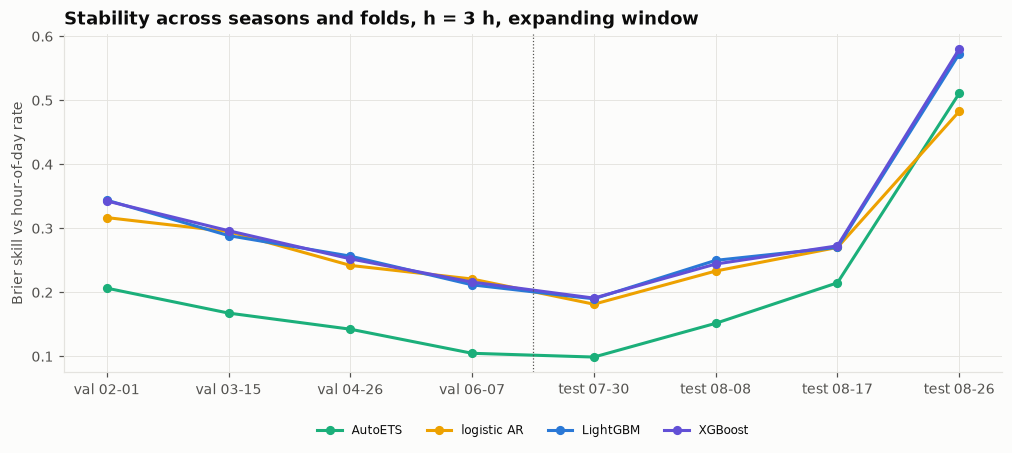

In [13]:
board_folds = backtest.summarize(preds, ["set", "window", "h", "fold"])
evaluation.plot_fold_stability(board_folds, h=3, window="expanding")

* **The ranking is stable in validation (Feb–Jun) and test (Aug)**: in every individual fold the boosters are best or tied-best and
  AutoETS is below them; the logistic AR is close to the boosters everywhere except the last test fold, where it falls slightly below AutoETS.
* The **level** of skill varies a lot between folds (≈ 0.1–0.6 vs the hour-of-day rate): it depends on how "regular" a period is,
  not on the model. The last test fold (26 Aug – 3 Sep) is unusually easy for all models; the summer folds before it are the hardest.
* So the conclusions do not depend on the summer-only test period — but single-period scores should not be over-interpreted.

## 9. Exponential smoothing experiments

Which ETS spec does AICc choose per oblast (first test training window)? ΔAICc is relative to the best spec of the oblast.

In [14]:
fold_start = backtest.folds()[0][0]
sel = evaluation.ets_selection(indicator, pd.Timestamp(config.REGIME_START).tz_convert("UTC"), fold_start - pd.Timedelta(hours=1))
print(sel["chosen"].value_counts().to_string())
sel.astype({c: float for c in sel.columns if c != "chosen"}).round(3)

chosen
A,N,N    19
A,N,A     5


,"ΔAICc A,N,N","ΔAICc A,N,A","ΔAICc A,A,A","ΔAICc A,Ad,A",chosen,alpha,gamma (seasonal)
Cherkaska oblast,0.000,253.844,265.826,259.723,"A,N,N",0.412,NaN
Chernihivska oblast,0.000,290.589,296.902,296.697,"A,N,N",0.500,NaN
Chernivetska oblast,0.000,190.522,194.558,196.577,"A,N,N",0.528,NaN
Dnipropetrovska oblast,8.321,0.000,4.036,6.056,"A,N,A",0.130,0.026
Donetska oblast,45.068,0.000,13.067,5.950,"A,N,A",0.194,0.031
Ivano-Frankivska oblast,0.000,228.089,232.125,234.144,"A,N,N",0.433,NaN
Kharkivska oblast,67.187,0.000,70.686,4.393,"A,N,A",0.137,0.033
Khersonska oblast,0.000,166.991,171.392,173.046,"A,N,N",0.417,NaN
Khmelnytska oblast,0.000,203.390,207.426,209.445,"A,N,N",0.611,NaN
Kirovohradska oblast,0.000,210.079,224.261,216.003,"A,N,N",0.391,NaN


In [15]:
ets_models = ["ETS(A,N,N)", "ETS(A,N,A)", "ETS(A,A,A)", "ETS(A,Ad,A)", "AutoETS"]
b = board[board.model.isin(ets_models) & (board.window == "expanding")]
b.pivot_table(index="model", columns=["set", "h"], values="brier").loc[ets_models].round(4)

set            test                 validation                
h                 1       3       6          1       3       6
model                                                         
ETS(A,N,N)   0.0753  0.0813  0.0879     0.0806  0.0979  0.1088
ETS(A,N,A)   0.0756  0.0811  0.0883     0.0813  0.0985  0.1097
ETS(A,A,A)   0.0754  0.0810  0.0882     0.0812  0.0985  0.1096
ETS(A,Ad,A)  0.0756  0.0811  0.0883     0.0813  0.0985  0.1097
AutoETS      0.0753  0.0814  0.0881     0.0804  0.0978  0.1088

* **AICc chooses the seasonal ETS(A,N,A) only for the five front-line oblasts** (Donetsk, Kharkiv, Sumy, Dnipropetrovsk, Zaporizhzhia).
  For all other oblasts the 24 seasonal states are not worth their cost (ΔAICc ≈ 90–300 against seasonality).
* **A trend never helps**: the estimated trend smoothing is ≈ 0, and (A,A,A) / (A,Ad,A) are practically identical to (A,N,A).
  That is expected for a bounded 0/1 indicator.
* **Out of sample, seasonality brings no consistent gain**: in the test set the seasonal specs are marginally better at h = 3 h,
  in the validation set (A,N,N) / AutoETS are marginally better at every horizon. All differences are ≤ 0.001 — within noise,
  matching the EDA (the daily cycle explains only a few percent of the hourly variance).
* ETS uses only the oblast's own history — the main reason it trails the feature-based models, which also see other oblasts.

## 10. Feature-based models: logistic AR vs LightGBM vs XGBoost

In [16]:
ml = ["logistic AR", "LightGBM", "XGBoost"]
board[board.model.isin(ml) & (board.window == "expanding")].pivot_table(
    index="model", columns=["set", "h"], values=["brier", "roc_auc_mean_per_oblast"]).round(4)

brier                                            roc_auc_mean_per_oblast                                           
set            test                 validation                                    test                 validation                
h                 1       3       6          1       3       6                       1       3       6          1       3       6
model                                                                                                                            
LightGBM     0.0550  0.0730  0.0826     0.0533  0.0836  0.0994                  0.8714  0.8356  0.7951     0.8842  0.8325  0.7910
XGBoost      0.0550  0.0727  0.0815     0.0533  0.0835  0.0991                  0.8695  0.8344  0.7969     0.8808  0.8338  0.7936
logistic AR  0.0565  0.0772  0.0862     0.0541  0.0847  0.0992                  0.8577  0.8373  0.7991     0.8808  0.8315  0.8049

In [17]:
f = board_folds[board_folds.model.isin(ml) & (board_folds.window == "expanding")]
wins = f.loc[f.groupby(["set", "h", "fold"])["brier"].idxmin()]
print("best feature-based model per (set, horizon, fold):", wins.model.value_counts().to_dict())
test = preds[preds.set == "test"]
ens = test.assign(**{"mean of 3": test[ml].mean(axis=1)})
eb = backtest.leaderboard(ens)
eb[(eb.window == "expanding") & eb.model.isin(ml + ["mean of 3"])].pivot_table(
    index="model", columns="h", values=["brier", "log_loss", "roc_auc_mean_per_oblast"]).round(4)

best feature-based model per (set, horizon, fold): {'XGBoost': 10, 'LightGBM': 9, 'logistic AR': 5}


brier                 log_loss                 roc_auc_mean_per_oblast                
h                 1       3       6        1       3       6                       1       3       6
model                                                                                               
LightGBM     0.0550  0.0730  0.0826   0.1789  0.2321  0.2628                  0.8714  0.8356  0.7951
XGBoost      0.0550  0.0727  0.0815   0.1786  0.2316  0.2596                  0.8695  0.8344  0.7969
logistic AR  0.0565  0.0772  0.0862   0.1852  0.2430  0.2741                  0.8577  0.8373  0.7991
mean of 3    0.0552  0.0735  0.0827   0.1798  0.2335  0.2629                  0.8745  0.8415  0.7998

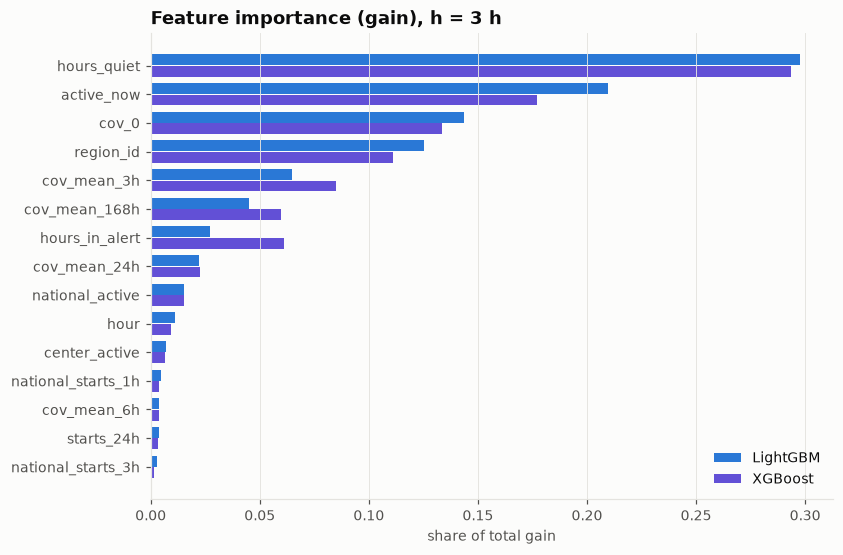

,hours_quiet,active_now,cov_0,region_id,cov_mean_3h,cov_mean_168h,hours_in_alert,cov_mean_24h,national_active,hour
LightGBM,0.298,0.210,0.143,0.125,0.065,0.045,0.027,0.022,0.015,0.011
XGBoost,0.294,0.177,0.134,0.111,0.085,0.060,0.061,0.023,0.015,0.009


In [18]:
imp = evaluation.feature_importance(panel, h=3)
evaluation.plot_feature_importance(imp, h=3)
imp.head(10).round(3).T

* **LightGBM and XGBoost are practically tied** (Brier differences ≤ 0.001 in both sets), XGBoost marginally ahead; across the
  24 (set, horizon, fold) combinations XGBoost is best 10×, LightGBM 9×, logistic AR 5×.
* **Logistic AR is close**, and has the best *mean per-oblast* ROC AUC on the test set at h = 3 h and 6 h — the boosters' advantage
  is mostly calibration across oblasts rather than ranking within one.
* **Averaging the three** gives the best per-oblast AUC at every horizon but not the best Brier score — no clear gain, not used.
* **Feature importance** is dominated by persistence (`hours_quiet`, `active_now`, `cov_0`) and oblast identity. Regional features
  have a small *total* gain — expected, since they matter for the rare onsets in the rear, a small share of all rows. Gain importance
  measures how much a feature is used overall, not how much it improves forecasts where it matters.

## 11. Per-oblast results, forecasts over time, ROC and calibration

Oblasts are sorted by their test base rate (in brackets).

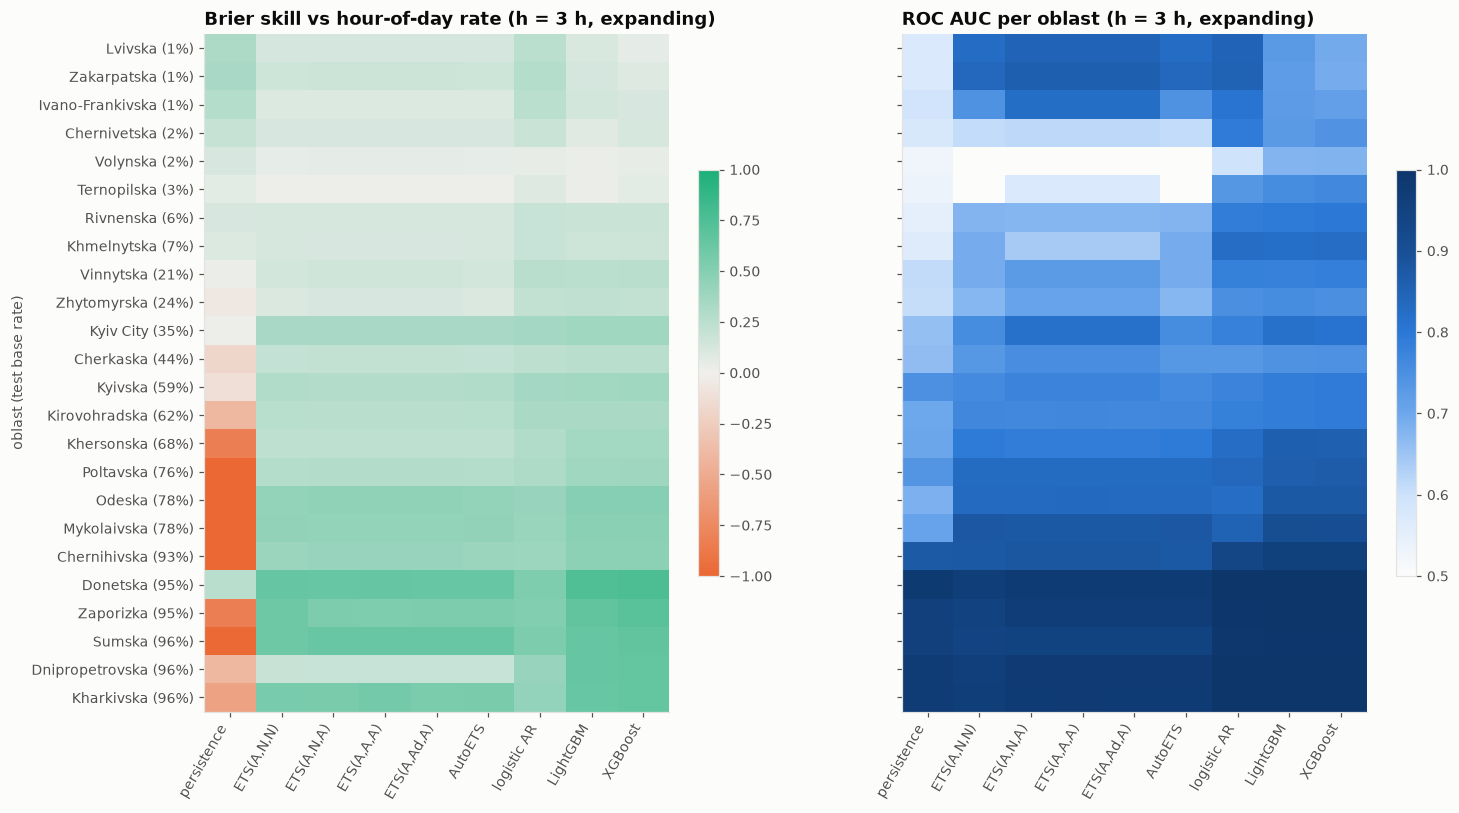

In [19]:
skill, auc = evaluation.plot_per_oblast(preds, h=3, window="expanding")

In [20]:
best = skill.drop(columns=["persistence"]).idxmax(axis=1)
pd.DataFrame({"best model (Brier)": best,
              "skill of best": skill.drop(columns=["persistence"]).max(axis=1).round(3),
              "LightGBM AUC": auc["LightGBM"].round(3), "XGBoost AUC": auc["XGBoost"].round(3)})

,best model (Brier),skill of best,LightGBM AUC,XGBoost AUC
region,,,,
Lvivska oblast,logistic AR,0.243,0.727,0.694
Zakarpatska oblast,logistic AR,0.274,0.723,0.690
Ivano-Frankivska oblast,logistic AR,0.249,0.723,0.717
Chernivetska oblast,logistic AR,0.174,0.728,0.742
Volynska oblast,"ETS(A,A,A)",0.050,0.676,0.679
Ternopilska oblast,logistic AR,0.085,0.757,0.763
Rivnenska oblast,logistic AR,0.188,0.793,0.799
Khmelnytska oblast,logistic AR,0.193,0.819,0.825
Vinnytska oblast,logistic AR,0.256,0.780,0.784


### Forecasts over time

One test week for four oblasts representing the four regimes. Grey: hours with an alert. Lines: P(alert within 3 h) issued at each hour.

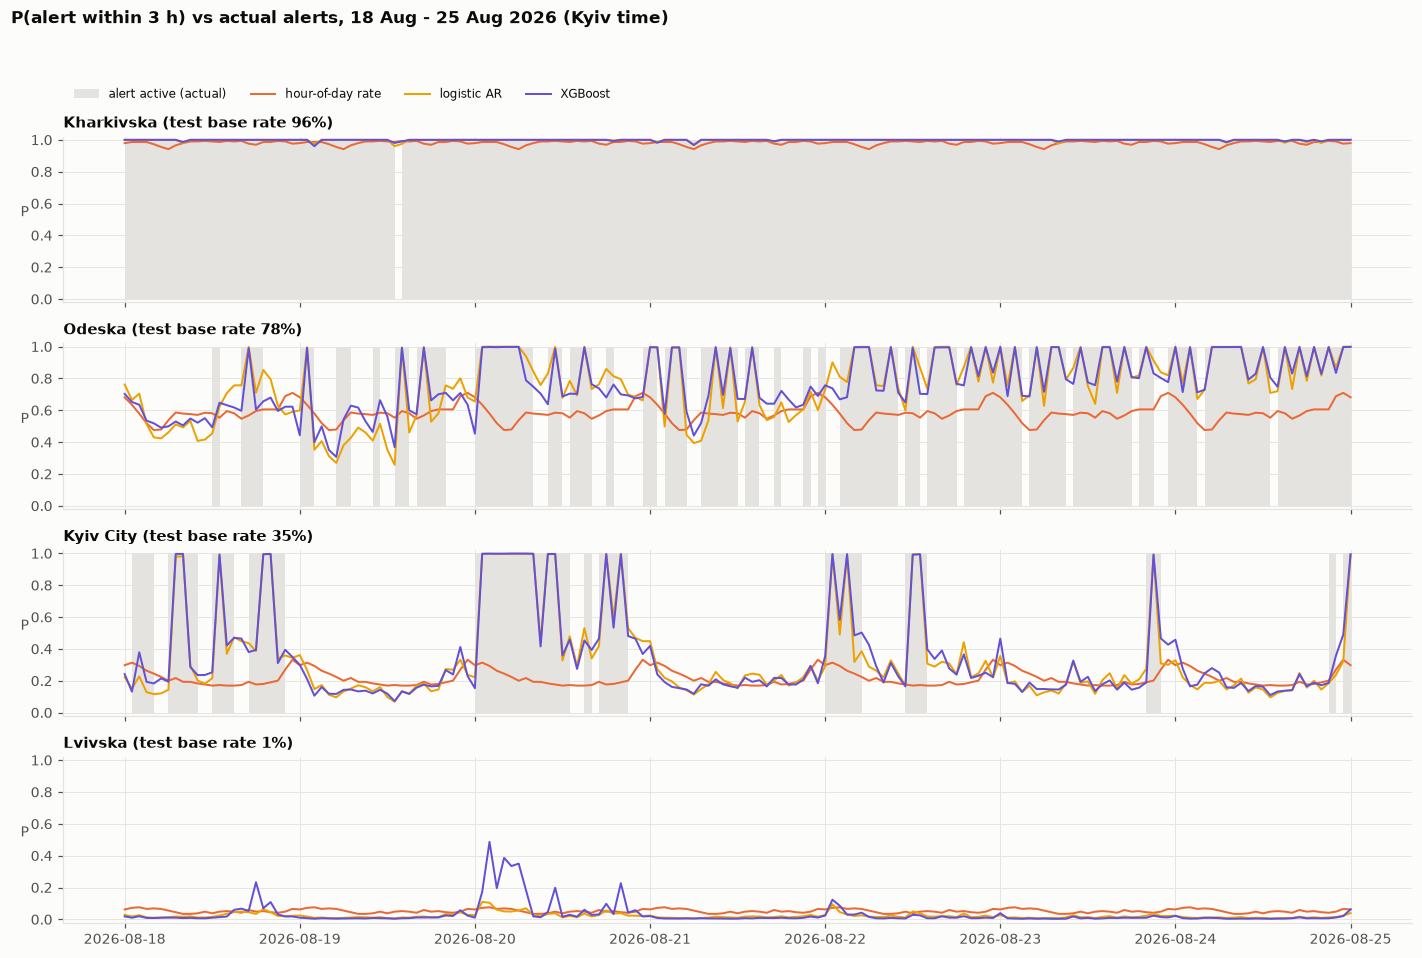

In [21]:
coverage = data.hourly_state(data.load_official(), end=data.regime_end())["coverage"]
evaluation.plot_predictions(preds, coverage, ["Kharkivska oblast", "Odeska oblast", "Kyiv City", "Lvivska oblast"],
                            start="2026-08-18", days=7, h=3)

* **Kharkiv (front)**: under alert almost continuously; every model predicts ≈ 1.
* **Odesa and Kyiv City**: the forecasts jump to ≈ 1 as soon as an alert starts and fall back when it ends — continuation is easy.
  *Before* an alert starts they mostly stay near the base level (≈ 0.2 for Kyiv): new alerts are anticipated only weakly, as section 7 showed.
* **Lviv (west)**: the probability stays near 0, with a short rise on 20 Aug when other oblasts were under alert (regional features)
  — no alert followed in Lviv that time.

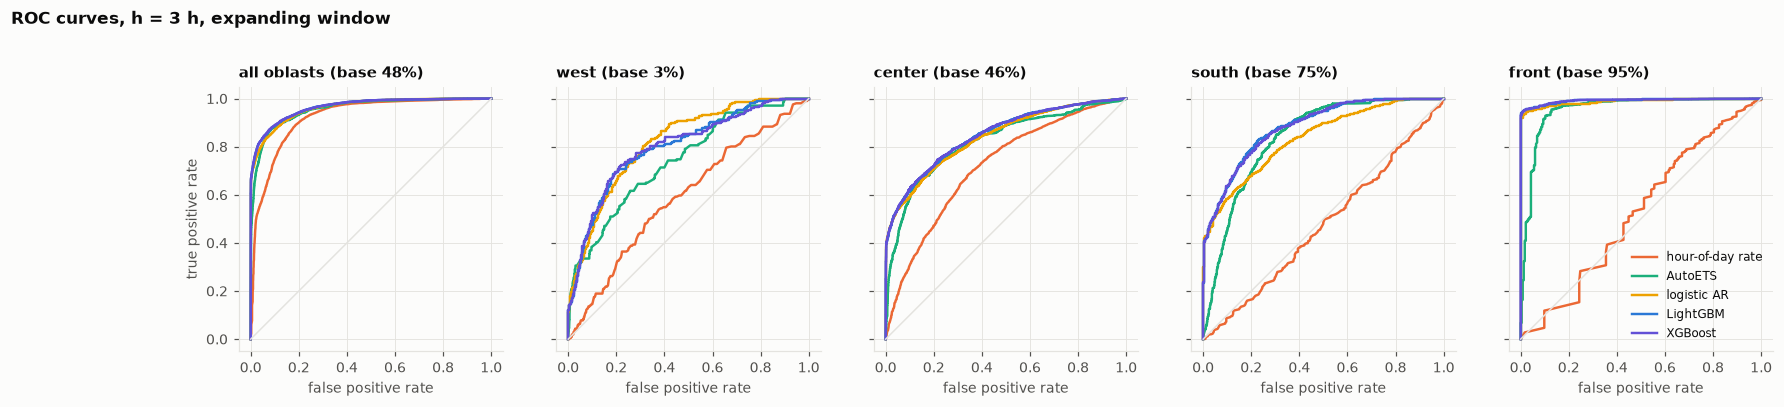

In [22]:
evaluation.plot_roc(preds, h=3, window='expanding')

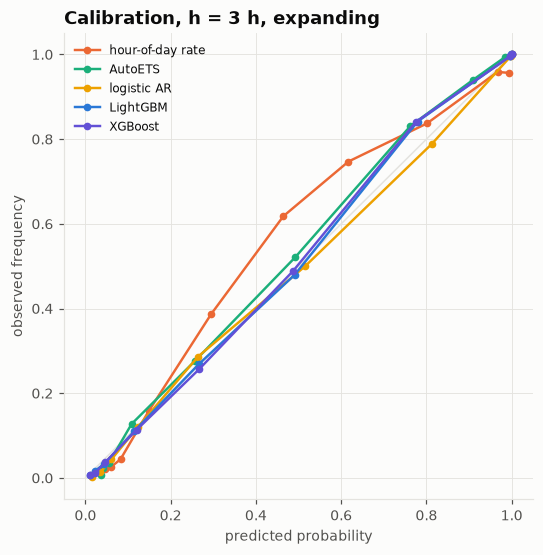

In [23]:
evaluation.plot_calibration(preds, h=3, window='expanding')

* **Middle oblasts (base rate 20–80 %)** — Kyiv, Cherkasy, Kirovohrad, Poltava, Odesa, Mykolaiv, Kherson: alerts are genuinely
  uncertain and the boosters add the most (Brier skill 0.25–0.5, AUC 0.75–0.9).
* **West (base rate 1–7 %)**: the logistic AR is the best model in 7 of 8 western oblasts; the boosters gain little there.
  The test weeks were much quieter than training (3.1 % vs 7.1 % of hours followed by an alert within 3 h) and Lviv and Zakarpattia
  had only 7 positive hours each, so model differences there are mostly noise.
* **Front line (base rate 93–96 %)**: every reasonable model is near-perfect (AUC ≈ 0.99).
* **Calibration**: the feature-based models are well calibrated across the whole probability range; the hour-of-day rate is not.

## 12. Conclusions

* **Final model: XGBoost, expanding window, tuned on the validation folds.** LightGBM is an equivalent alternative; the logistic AR
  is a strong, interpretable runner-up and better in the quiet western oblasts.
* **Honest skill.** Over all hours, Brier skill vs the hour-of-day rate is 0.51 / 0.36 / 0.25 at 1 / 3 / 6 h on the test set — but most of
  it comes from predicting that a running alert continues. **For the real question — will a new alert start within 3 h? — the skill is
  0.19 on the test set and 0.09 on the validation set, with a per-oblast ROC AUC of about 0.72–0.76.**
* **Robustness.** The model ranking is identical on the validation folds (Feb–Jun) and the test folds (Aug); hyperparameters matter little.
* **What drives the forecasts**: the oblast's current state and recent history; the regional state helps for new alerts in the rear;
  seasonality (daily, weekly) adds little out of sample.
* **Limitations.** Evaluation stops at 4 Sep 2026, when the alert system changed and the official data feed stopped (`eda.ipynb`, section 1).
  The model predicts the *official alert*, not the threat itself; under the yellow/red system it would have to be re-trained on new data.
  Better early warning of new alerts would need information the alert history does not contain — e.g. Air Force reports of launches
  and drone movements (Telegram `@kpszsu`), the natural next step.